# Stock movement forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture.

In [1]:
import time 
import pandas
import random
import json, argparse
import time

# ML
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
import seaborn as sns
from plotly import graph_objects as go
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import confusion_matrix, roc_auc_score, classification_report
from bayes_opt import BayesianOptimization

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import models_classification as Models
import utils
import dataset as Dataset

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print('Using device:', device)

# Set the seed
SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
np.random.seed(SEED)

Using device: cuda:0


## Load Data

In [2]:
df = pd.read_parquet('./Data/FI-2010-Cleaned/NoAuction/Zscore/WRT1V.parquet')
df = df.head(20000)
df.drop(columns=['Day'], inplace=True)

target_cols = ['Label_10', 'Label_20', 'Label_30', 'Label_50', 'Label_100']
# Set target cols to dtype int
df[target_cols] = df[target_cols].astype(int)

df.head()

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10,Label_10,Label_20,Label_30,Label_50,Label_100
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,-0.499588,1.236425,-0.444236,1.243820,-0.278126,1,1,1,1,1
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,1,1,1,1
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,2,2,1,1,1
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,-0.339924,1.233373,-0.228680,1.245871,-0.448846,1,0,0,1,1


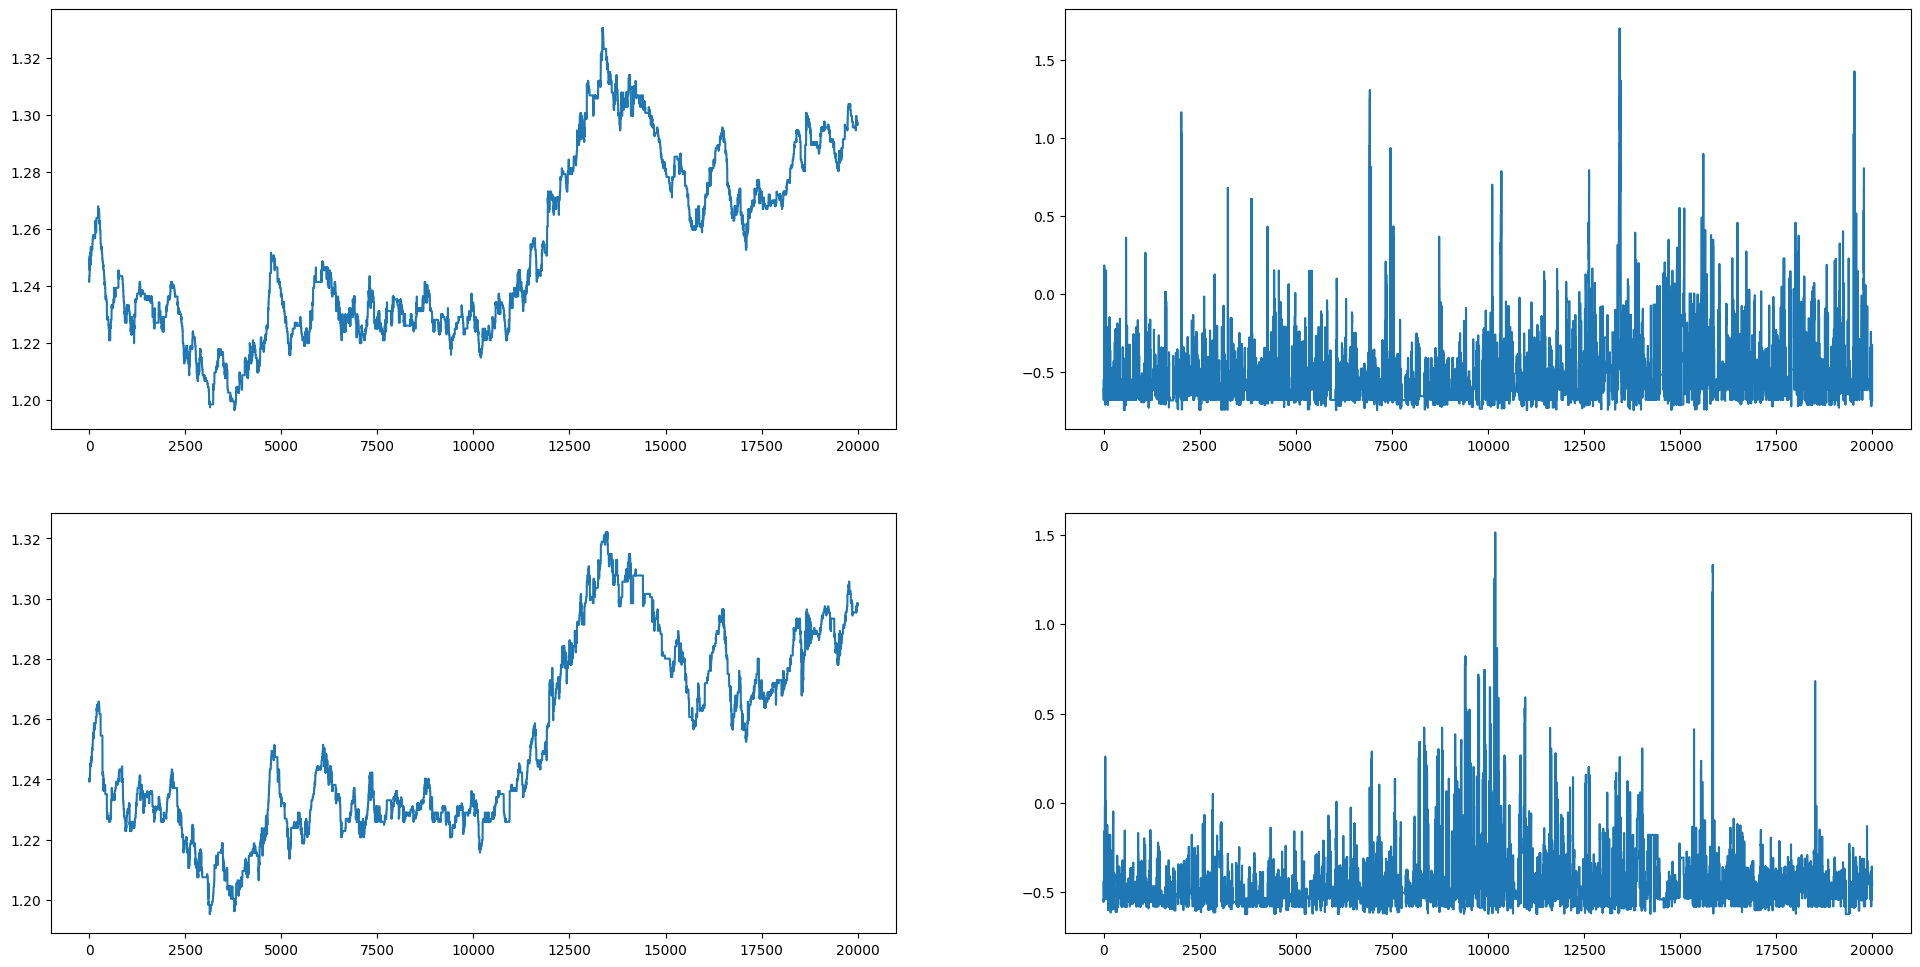

In [3]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [4]:
logreturn = lambda x: np.log(x) - np.log(x.shift(1))

price_cols = [col for col in df.columns if 'P_' in col]
df[price_cols] = df[price_cols].apply(logreturn, axis=0)
df.dropna(inplace=True)

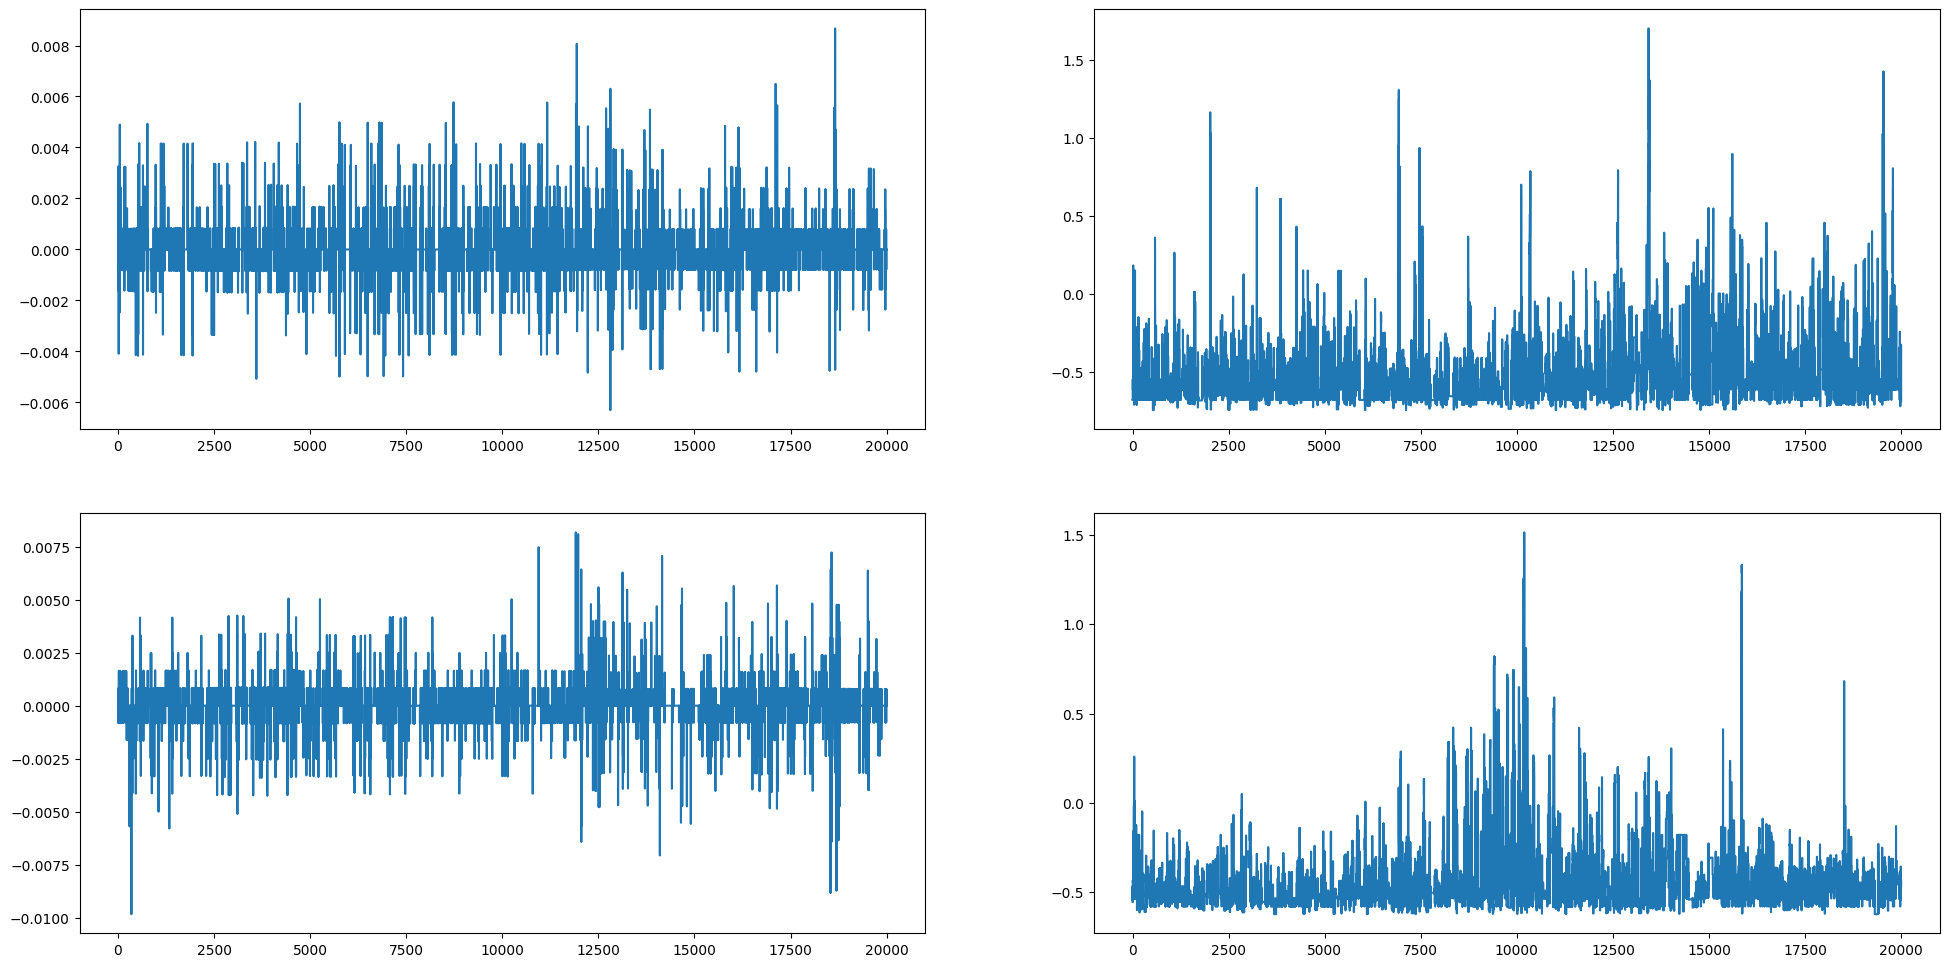

In [5]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(df['P_Ask_1'])
axs[0,1].plot(df['V_Ask_1'])
axs[1,0].plot(df['P_Bid_1'])
axs[1,1].plot(df['V_Bid_1'])
plt.show()

In [6]:
# Split the dataframe into train and test
df_train, df_val, df_test = utils.DataTools.train_val_test_split(df)

# Split covariates and response variable(s)
X_train, y_train = utils.DataTools.split_x_y(df_train, target_cols)
X_val, y_val     = utils.DataTools.split_x_y(df_val, target_cols)
X_test, y_test   = utils.DataTools.split_x_y(df_test, target_cols)

# Standardize the covariates
scaler_X = preprocessing.StandardScaler()
X_train = scaler_X.fit_transform(X_train)
X_val = scaler_X.transform(X_val)
X_test = scaler_X.transform(X_test)

# Build tensors 
X_train, X_val, X_test = utils.DataTools.numpy_to_tensor( X_train, X_val, X_test, device=device, dtype=torch.float32 )
y_train, y_val, y_test = utils.DataTools.numpy_to_tensor( y_train, y_val, y_test, device=device, dtype=torch.long )

# Build TimeSeriesDataset
SEQ_LEN_X = 50
SEQ_LEN_Y = 1
OFFSET = 0
dataset_train = Dataset.TimeSeriesDataset(
    X         = X_train,
    y         = y_train,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_val = Dataset.TimeSeriesDataset(
    X         = X_val,
    y         = y_val,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)
dataset_test = Dataset.TimeSeriesDataset(
    X         = X_test,
    y         = y_test,
    seq_len_x = SEQ_LEN_X,
    seq_len_y = SEQ_LEN_Y,
    offset    = OFFSET,
    channels  = False,
    task      = Dataset.TimeSeriesDataset.Task.CLASSIFICATION
)

# Build TimeSeriesLoader
BATCH_SIZE = 32
dataloader_train = Dataset.TimeSeriesLoader(
    dataset = dataset_train,
    batch_size = BATCH_SIZE,
    shuffle = True
)
dataloader_val = Dataset.TimeSeriesLoader(
    dataset = dataset_val,
    batch_size = BATCH_SIZE,
    shuffle = False
)
dataloader_test = Dataset.TimeSeriesLoader(
    dataset = dataset_test,
    batch_size = 1024,
    shuffle = False
)

In [7]:
print(f'Train dataset: {len(dataset_train)} samples')
print(f'Test dataset: {len(dataset_test)} samples')

Train dataset: 13949 samples
Test dataset: 2951 samples


## Models

In [8]:
def loss_fn(y_pred, y, criterion = nn.CrossEntropyLoss() ):
    loss = 0
    for i in range(y_pred.shape[1]):
        loss += criterion(y_pred[:, i, :], y[:, i])
    return loss

### Basic LSTM

In [9]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [10]:
pbounds = {
    # Architecture hyperparameters
    'hidden_size': (32, 128),
    'dropout': (0.0, 0.2),
    # Training hyperparameters
    'lr': (1e-5, 1e-3),
    'n_epochs': (50, 150),
}

wrapper = lambda hidden_size, dropout, lr, n_epochs: utils.ModelTools.ht_train_wrapper(
    dataset_train   = dataset_train,
    dataset_val     = dataset_val,
    model_class     = Models.LSTM,
    device          = device,
    criterion       = loss_fn,
    params          = {
        'input_size': X_train.shape[1],
        'output_size': y_train.shape[1]*3,
        'hidden_size': round(hidden_size),
        'dropout': dropout,
        'lr': lr,
        'batch_size': 32,
        'n_epochs': round(n_epochs),
    },
)

bayesian_optimizer = BayesianOptimization(
    f=wrapper,
    pbounds=pbounds,
    random_state=SEED,
    verbose=2,
)

In [11]:
t0 = time.time()
bayesian_optimizer.maximize(init_points=5, n_iter=20)
tf = time.time()

elapsed_time = tf - t0
print(f"Bayesian optimization took {elapsed_time:.2f} seconds.")

best_params = bayesian_optimizer.max['params']

|   iter    |  target   |  dropout  | hidden... |    lr     | n_epochs  |
-------------------------------------------------------------------------


Training:   0%|          | 0/110 [00:00<?, ?it/s]

| 1         | -4.583    | 0.07491   | 123.3     | 0.0007347 | 109.9     |


Training:   0%|          | 0/137 [00:00<?, ?it/s]

| 2         | -4.616    | 0.0312    | 46.98     | 6.75e-05  | 136.6     |


Training:   0%|          | 0/147 [00:00<?, ?it/s]

... (41 outputs left out)

Training:   0%|          | 0/84 [00:00<?, ?it/s]

| 24        | -4.357    | 0.161     | 38.0      | 0.0009241 | 84.18     |


Training:   0%|          | 0/82 [00:00<?, ?it/s]

| 25        | -4.443    | 0.1059    | 36.86     | 0.0001889 | 81.78     |
Bayesian optimization took 4904.36 seconds.


### Training best model

In [15]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': round(best_params['hidden_size']),
    'num_layers': 2,
    'dropout': best_params['dropout']
}
model = Models.LSTM(**params).to(device)

# Define loss function and optimizer
learning_rate = best_params['lr']
n_epochs = round(best_params['n_epochs'])
criterion = loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'LSTM1',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    train_loader = dataloader_train,
    val_loader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

Training:   0%|          | 0/84 [00:00<?, ?it/s]

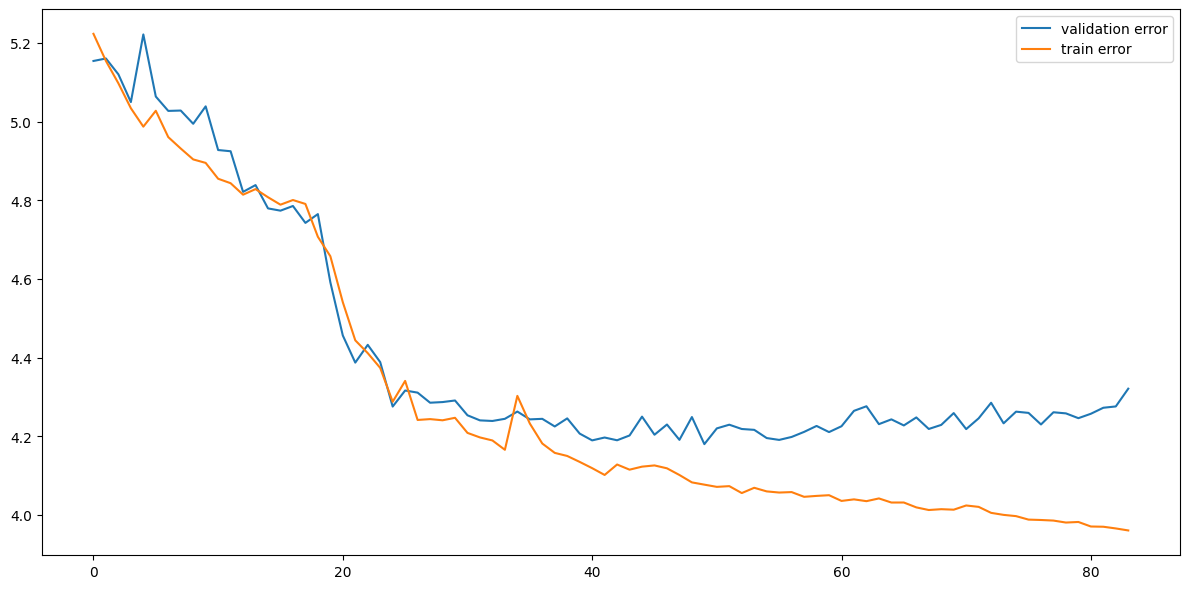

In [16]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [20]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true, axis=0)
pred = np.concatenate(pred, axis=0)
pred = np.argmax(pred, axis=2)

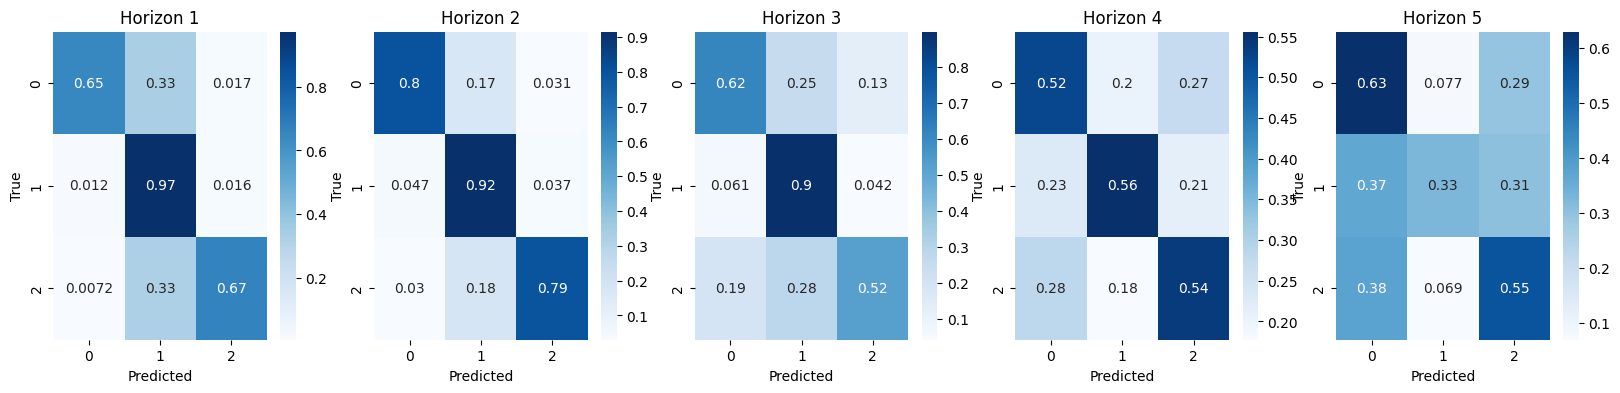

In [21]:
conf_matrixes = []
for i in range(true.shape[1]):
    conf_matrix = confusion_matrix(true[:, i], pred[:, i], normalize='true')
    conf_matrixes.append(conf_matrix)
    
fig, axs = plt.subplots(1, true.shape[1], figsize=(20, 4))
for i, ax in enumerate(axs):
    sns.heatmap(conf_matrixes[i], annot=True, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Horizon {i+1}')
plt.show()

In [22]:
# 5 classification reports
for i in range(true.shape[1]):
    print(f'Classification report {i}')
    print(classification_report(true[:, i], pred[:, i], zero_division=0))
    print('\n')

Classification report 0
              precision    recall  f1-score   support

           0       0.94      0.65      0.77       645
           1       0.81      0.97      0.88      1749
           2       0.90      0.67      0.77       557

    accuracy                           0.84      2951
   macro avg       0.89      0.76      0.81      2951
weighted avg       0.86      0.84      0.84      2951



Classification report 1
              precision    recall  f1-score   support

           0       0.88      0.80      0.84       836
           1       0.83      0.92      0.87      1417
           2       0.87      0.79      0.83       698

    accuracy                           0.85      2951
   macro avg       0.86      0.84      0.85      2951
weighted avg       0.86      0.85      0.85      2951



Classification report 2
              precision    recall  f1-score   support

           0       0.72      0.62      0.67       962
           1       0.70      0.90      0.78      1201

## Astice

In [9]:
dataloader_train.dataset.channels = False
dataloader_val.dataset.channels = False
dataloader_test.dataset.channels = False

In [10]:
pbounds = {
    # Architecture hyperparameters
    'hidden_size': (32, 128),
    'dropout_rate': (0.0, 0.2),
    'lstm_size' : (32, 128),
    'smooth_conv_channels': (2, 32),
    # Training hyperparameters
    'lr': (1e-5, 1e-3),
    'n_epochs': (50, 150),
}

wrapper = lambda hidden_size, dropout_rate, lstm_size, smooth_conv_channels, lr, n_epochs: utils.ModelTools.ht_train_wrapper(
    dataset_train   = dataset_train,
    dataset_val     = dataset_val,
    model_class     = Models.Astice,
    device          = device,
    criterion       = loss_fn,
    params          = {
        'input_size': X_train.shape[1],
        'output_size': y_train.shape[1]*3,
        'hidden_size': round(hidden_size),
        'dropout_rate': dropout_rate,
        'lstm_size': round(lstm_size),
        'smooth_conv_channels': round(smooth_conv_channels),
        'lr': lr,
        'batch_size': BATCH_SIZE,
        'n_epochs': round(n_epochs),
    },
)

bayesian_optimizer = BayesianOptimization(
    f=wrapper,
    pbounds=pbounds,
    random_state=SEED,
    verbose=2,
)

In [11]:
t0 = time.time()
bayesian_optimizer.maximize(init_points=5, n_iter=20)
tf = time.time()

elapsed_time = tf - t0
print(f"Bayesian optimization took {elapsed_time:.2f} seconds.")

best_params = bayesian_optimizer.max['params']

|   iter    |  target   | dropou... | hidden... |    lr     | lstm_size | n_epochs  | smooth... |
-------------------------------------------------------------------------------------------------


Training:   0%|          | 0/66 [00:00<?, ?it/s]

/orfeo/cephfs/home/dssc/gpintus/Jupyter/jupyter/lib64/python3.9/site-packages/torch/nn/modules/conv.py:306: UserWarning: Attempt to open cnn_infer failed: handle=0 error: libcudnn_cnn_infer.so.8: cannot open shared object file: No such file or directory (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:81.)
  return F.conv1d(input, weight, bias, self.stride,


| 1         | -4.638    | 0.07491   | 123.3     | 0.0007347 | 89.47     | 65.6      | 6.68      |


Training:   0%|          | 0/52 [00:00<?, ?it/s]

| 2         | -4.514    | 0.01162   | 115.2     | 0.0006051 | 99.97     | 52.06     | 31.1      |


... (42 outputs left out)

Training:   0%|          | 0/78 [00:00<?, ?it/s]

| 24        | -4.423    | 0.1855    | 50.88     | 0.0006686 | 57.62     | 77.98     | 17.21     |


Training:   0%|          | 0/80 [00:00<?, ?it/s]

| 25        | -4.535    | 0.0       | 52.13     | 0.001     | 54.27     | 79.98     | 20.56     |
Bayesian optimization took 5034.55 seconds.


In [14]:
# Create the model
params = {
    'input_size': X_train.shape[1],
    'output_size': 3*y_train.shape[1],
    'hidden_size': round(best_params['hidden_size']),
    'num_layers': 2,
    'dropout_rate': best_params['dropout_rate']
}
model = Models.Astice(**params).to(device)

# Define loss function and optimizer
learning_rate = best_params['lr']
n_epochs = round(best_params['n_epochs'])
criterion = loss_fn
optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)

# Train the model
training_info = utils.ModelTools.train(
    model_id = 'Astice1',
    model = model,
    criterion = criterion,
    optimizer = optimizer,
    trainloader = dataloader_train,
    valloader = dataloader_val,
    n_epochs = n_epochs,
    save = False,
    device = device
)

TypeError: __init__() got an unexpected keyword argument 'num_layers'

In [ ]:
epochs_list = list(range(0,epochs))
plt.figure(figsize=(12,6))
plt.plot(epochs_list, training_info['val_loss'],  label = "validation error")
plt.plot(epochs_list, training_info['train_loss'], label = "train error")
plt.legend(loc = 'best')
plt.tight_layout()
plt.show()

In [ ]:
true = []
pred = []

# Evaluate the model
with torch.no_grad():
    for inputs, labels in dataloader_test:
        inputs, labels = inputs.to(device), labels.to(device)
        outputs = model(inputs)
        true.append(labels.cpu().numpy())
        pred.append(outputs.cpu().numpy())

true = np.concatenate(true, axis=0)
pred = np.concatenate(pred, axis=0)
pred = np.argmax(pred, axis=2)

In [ ]:
conf_matrixes = []
for i in range(true.shape[1]):
    conf_matrix = confusion_matrix(true[:, i], pred[:, i], normalize='true')
    conf_matrixes.append(conf_matrix)
    
fig, axs = plt.subplots(1, true.shape[1], figsize=(20, 4))
for i, ax in enumerate(axs):
    sns.heatmap(conf_matrixes[i], annot=True, cmap='Blues', ax=ax)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(f'Horizon {i+1}')
plt.show()

In [ ]:
# 5 classification reports
for i in range(true.shape[1]):
    print(f'Classification report {i}')
    print(classification_report(true[:, i], pred[:, i], zero_division=0))
    print('\n')